# Dissertação de Mestrado: Análise Alométrica Global Bacia–Mancha Urbana–Microplásticos Costeiros
## Análise Multi-Continental via GebcoCutter e Verificação da Correlação Global

**Pesquisador:** Thiago  
**Orientador:** Prof. Dr. Erneson A. Oliveira  
**Bases de Dados:** GPW v4 (Contagem Populacional CIESIN 2020), GEBCO 2026 (Batimetria e Topografia Global) e NOAA NCEI (Microplásticos Marinhos Globais $< 5\ \mathrm{mm}$)

---

### Resumo Metodológico e Fundamentação Teórica
Este notebook estende a metodologia da dissertação para o **mundo inteiro**, particionando a superfície do planeta em suas grandes massas de terra continentais (ilhas) utilizando a lógica de percolação do `GebcoCutter`:

1. **Segmentação Continental (GebcoCutter):**
   - Recorte independente das 5 grandes massas continentais: **North & Central America**, **South America**, **Europe & Eurasia**, **Africa** e **Australia**.

2. **Topografia, Área via Triângulos Esféricos (L'Huilier) e Bacias Hidrográficas (IPBA Global):**
   - Altura de corte $h^* = 0$ (nível do mar) para cada continente.
   - **Cálculo de Área via Composição de Dois Triângulos Esféricos (Eqs. 3 e 4 de Oliveira et al., 2019):** A área de cada sítio é obtida somando dois triângulos esféricos pelo **Teorema de L'Huilier** com arestas geodésicas de **Haversine**.
   - Rodada única do IPBA com corte cumulativo de 95% de área, descartando bacias residuais de borda.

3. **Calibração Dinâmica do CCA Regional via Lei de Zipf:**
   - Para cada continente, calibra-se a matriz de parâmetros $(D^*, \ell)$ de forma independente a partir da contagem de pessoas por pixel (`gpw_v4_population_count_rev11_2020_30_sec.tif`) dividida pela área esférica de cada sítio, selecionando o par com expoente de Zipf mais próximo de $1$ ($\alpha \approx 1$).

4. **Pareamento com Raio Adaptativo Individualizado por Sink:**
   - Expansão de raio individualizada por sink ($r_i^* \le 0{,}5 \cdot d_{\min}(\mathrm{sink\_outro})$), garantindo que nenhuma foz invada o estuário vizinho e assegurando contagem estritamente exclusiva (zero duplicação).

5. **Investigação e Filtro Estrito de Microplásticos Verificados ($< 5\ \mathrm{mm}$):**
   - Comparação sistemática entre pellets industriais pré-produção (*Nurdle Patrol*) e **microplásticos secundários verificados por malha micrométrica ($0{,}02\text{ a }5{,}0\ \mathrm{mm}$, em $\mathrm{pieces/m^3}$)**, avaliando a confirmação da lei alométrica populacional em escala planetária.


In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from IPython.display import Image, display

# Configurar caminhos do projeto
NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from pipeline.gebco_cutter import GRANDES_ILHAS
from scripts.find_optimal_cleaning_pipeline import verificar_ganho_triangulos_esfericos
from geracao_graficos.estilo_erneson import (
    aplicar_estilo,
    salvar,
    rotulo_painel,
    rotulo_canto,
    FIGSIZE_MAPA_MUNDI,
    WORLD_GEOJSON,
)
from geracao_graficos.figuras import plotar_comparacao_ilhas_global

aplicar_estilo()
print("Ambiente configurado com sucesso e estilo visual Erneson Oliveira aplicado.")
display(verificar_ganho_triangulos_esfericos())


Ambiente configurado com sucesso e estilo visual Erneson Oliveira aplicado.


,cenario,area_spherical_triangles_km2,area_zonal_exact_km2,area_diff_approx_km2,area_naive_no_lat_km2,diff_lhuilier_vs_approx_pct,erro_naive_sem_lat_pct
0,"Baixa Latitude (Equador, 0° - pixel GPW 30 arc...",0.860558,0.860558,0.860558,0.860558,8.814154e-08,0.000002
1,Média Latitude (45° - pixel GPW 30 arc-sec),0.608506,0.608506,0.608506,0.860558,1.762386e-07,41.421354
2,Alta Latitude (70° - pixel GPW 30 arc-sec),0.294328,0.294328,0.294328,0.860558,3.789524e-07,192.380437
3,"Baixa Latitude (Equador, 0° - pixel GEBCO 15 a...",0.215139,0.215139,0.215139,0.215139,2.203540e-08,0.000001
4,Alta Latitude (70° - pixel GEBCO 15 arc-sec),0.073582,0.073582,0.073582,0.215139,9.481909e-08,192.380436


## 1. Distribuição Global das Estações de Coleta de Microplásticos (NOAA NCEI)

Carregamos as observações globais de microplásticos marinhos ($< 5\ \mathrm{mm}$) da base NOAA NCEI e geramos o mapa-múndi oficial da dissertação (**Figura F3**).


In [2]:
noaa_path = REPO_ROOT / "dados" / "noaa_microplastic" / "Hub_Microplastics_Replace_2485283804436522212.geojson"
with open(noaa_path, "r", encoding="utf-8") as f:
    gj_noaa = json.load(f)

pts_all = []
for feat in gj_noaa.get("features", []):
    props = feat.get("properties") or {}
    lat = props.get("Latitude__degree_")
    lon = props.get("Longitude_degree_")
    if lat is not None and lon is not None:
        pts_all.append({
            "latitude": float(lat),
            "longitude": float(lon),
            "medium": str(props.get("Medium", "")).strip(),
            "short_ref": str(props.get("Short_Reference", "")).strip(),
        })

df_noaa_global = pd.DataFrame(pts_all)
print(f"Total de observações registradas na base NOAA: {len(df_noaa_global):,}")
print("Distribuição por categoria de meio amostrado (Medium):")
print(df_noaa_global["medium"].value_counts())


Total de observações registradas na base NOAA: 29,076
Distribuição por categoria de meio amostrado (Medium):
medium
Ocean water       16988
Nurdle Patrol     10615
Beach               893
Ocean sediment      580
Name: count, dtype: int64


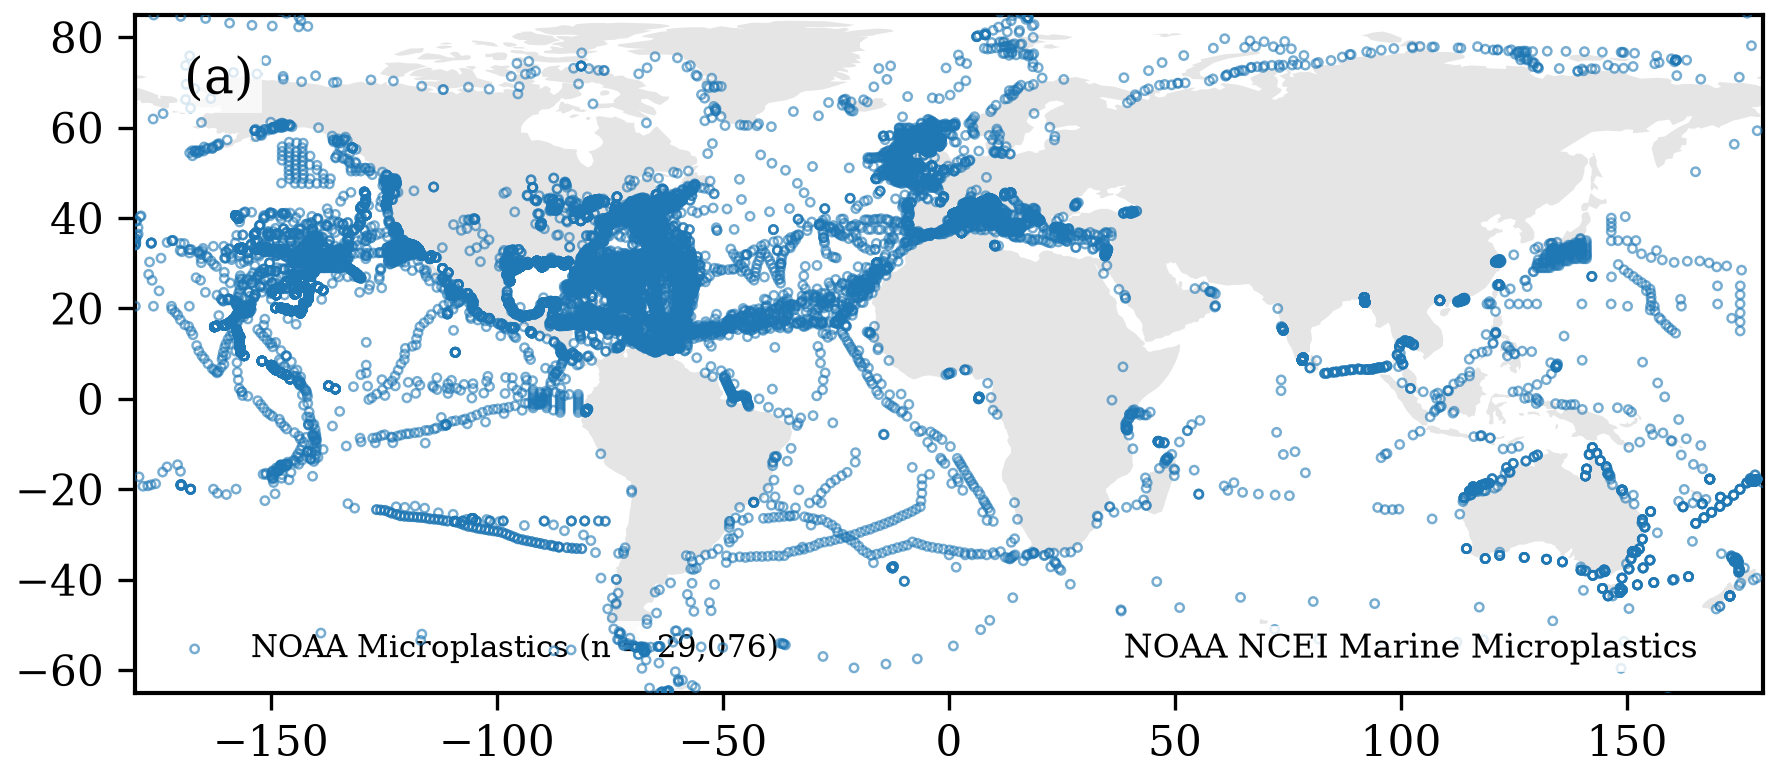

In [3]:
def plotar_mapa_mundi_noaa(df_mp, output_basepath):
    fig, ax = plt.subplots(figsize=FIGSIZE_MAPA_MUNDI)
    ax.set_xlim(-180.0, 180.0)
    ax.set_ylim(-65.0, 85.0)
    ax.set_aspect("equal")

    # Contorno continental sutil em cinza claro
    if WORLD_GEOJSON.is_file():
        with open(WORLD_GEOJSON, "r", encoding="utf-8") as f:
            gj = json.load(f)
        for feat in gj.get("features", []):
            geom = feat.get("geometry", {})
            gtype = geom.get("type")
            coords = geom.get("coordinates", [])
            if gtype == "Polygon":
                for ring in coords:
                    poly = Polygon(ring, facecolor="#e5e5e5", edgecolor="none", zorder=1)
                    ax.add_patch(poly)
            elif gtype == "MultiPolygon":
                for poly_coords in coords:
                    for ring in poly_coords:
                        poly = Polygon(ring, facecolor="#e5e5e5", edgecolor="none", zorder=1)
                        ax.add_patch(poly)

    ax.scatter(
        df_mp["longitude"], df_mp["latitude"],
        s=4.0, edgecolors="C0", facecolors="none", lw=0.6, alpha=0.6,
        label=f"NOAA Microplastics (n = {len(df_mp):,})", zorder=10
    )

    ax.legend(loc="lower left", frameon=True, framealpha=0.88, facecolor="white", edgecolor="none", fontsize=7.5)
    rotulo_painel(ax, "a", dentro=True)
    rotulo_canto(ax, "NOAA NCEI Marine Microplastics", canto="lower right", fontsize=8.0)

    return salvar(fig, output_basepath)

fig_f3_base = REPO_ROOT / "relatorios" / "figuras" / "f3_microplastics_world_map"
png_f3, pdf_f3 = plotar_mapa_mundi_noaa(df_noaa_global, fig_f3_base)
display(Image(filename=str(png_f3)))


## 2. Metodologia GebcoCutter: Segmentação por Grandes Ilhas Continentais

Inspirado na rotina `GebcoCutter` (Prof. Erneson Oliveira), o pipeline particiona o planeta nas suas grandes massas de terra continentais:
- **North & Central America** (`lon: [-128, -65], lat: [8, 52]`)
- **South America** (`lon: [-82, -34], lat: [-56, 13]`)
- **Europe & Eurasia** (`lon: [-15, 45], lat: [35, 72]`)
- **Africa** (`lon: [-18, 52], lat: [-35, 38]`)
- **Australia** (`lon: [112, 155], lat: [-45, -10]`)

Para cada uma das ilhas, o pipeline executou:
1. Recorte do relevo GEBCO e extração de sinks costeiros.
2. Delimitação das bacias via rodada única do IPBA (95% da área acumulada calculada via Triângulos Esféricos / L'Huilier).
3. Recorte populacional GPW v4 (contagem de pessoas por pixel) e calibração dinâmica de Zipf ($D^* \le 5000$ hab/km² e $\ell$).
4. Particionamento das manchas urbanas do CCA entre as bacias receptoras somando a população dos pixels de cada bacia.
5. Atribuição com **raio individualizado por sink** (sem sobreposição entre bacias).


In [4]:
out_ilhas_dir = REPO_ROOT / "relatorios" / "ilhas"

# Exibir os parâmetros calibrados e o total de bacias de cada grande ilha
resumos = []
for nome, info in GRANDES_ILHAS.items():
    slug = nome.lower().replace(" & ", "_").replace(" ", "_")
    pop_csv = out_ilhas_dir / f"populacao_todas_bacias_{slug}.csv"
    zipf_csv = out_ilhas_dir / f"matriz_zipf_{slug}.csv"
    
    if pop_csv.is_file() and zipf_csv.is_file():
        df_p = pd.read_csv(pop_csv)
        df_z = pd.read_csv(zipf_csv)
        best = df_z.iloc[(df_z['alpha']-1.0).abs().argsort()[:1]].iloc[0]
        resumos.append({
            "Massa Continental": nome,
            "Total de Bacias Hidrográficas": len(df_p),
            "População Total Contabilizada": f"{df_p['total_population'].sum():,.0f}",
            "População Urbana CCA": f"{df_p['urban_population'].sum():,.0f}",
            "D* Calibrado (hab/km²)": float(best['d_star']),
            "L Calibrado (km)": float(best['l_cutoff']),
            "Zipf Alpha": f"{float(best['alpha']):.3f}",
            "Zipf R²": f"{float(best['r2']):.3f}",
        })

df_resumo_ilhas = pd.DataFrame(resumos)
df_resumo_ilhas


,Massa Continental,Total de Bacias Hidrográficas,População Total Contabilizada,População Urbana CCA,D* Calibrado (hab/km²),L Calibrado (km),Zipf Alpha,Zipf R²
0,North & Central America,1113,"538,558,424","116,506,242",4000.0,6.0,1.000,0.968
1,South America,388,"367,463,034","270,963,729",100.0,4.0,0.998,0.982
2,Europe & Eurasia,2850,"754,777,647","171,293,482",3000.0,1.5,0.990,0.969
3,Africa,386,"1,354,004,225","150,205,542",5000.0,8.0,0.983,0.907
4,Australia,357,"12,086,493","662,696",5000.0,1.0,1.094,0.980


## 3. Consolidação do Dataset Global com Nurdle Patrol

Unimos os dados de todas as ilhas que possuíam amostragem do protocolo Nurdle Patrol (`relatorios/dados_pareados_global_todas_ilhas.csv`).


In [5]:
global_csv = REPO_ROOT / "relatorios" / "dados_pareados_global_todas_ilhas.csv"
df_global_nurdles = pd.read_csv(global_csv)

print(f"Total de bacias no dataset global de Nurdles: {len(df_global_nurdles)}")
print("Bacias por massa continental:")
print(df_global_nurdles["island_name"].value_counts())


Total de bacias no dataset global de Nurdles: 192
Bacias por massa continental:
island_name
North & Central America    164
Europe & Eurasia            13
Africa                      10
South America                3
Australia                    2
Name: count, dtype: int64


## 4. Análise Alométrica Global Preliminar com Nurdles (Figura F7 Global)

Geramos a **Figura F7 Global**, exibindo a alometria urbana e o controle por área de drenagem com os dados brutos de pellets industriais (Nurdles).


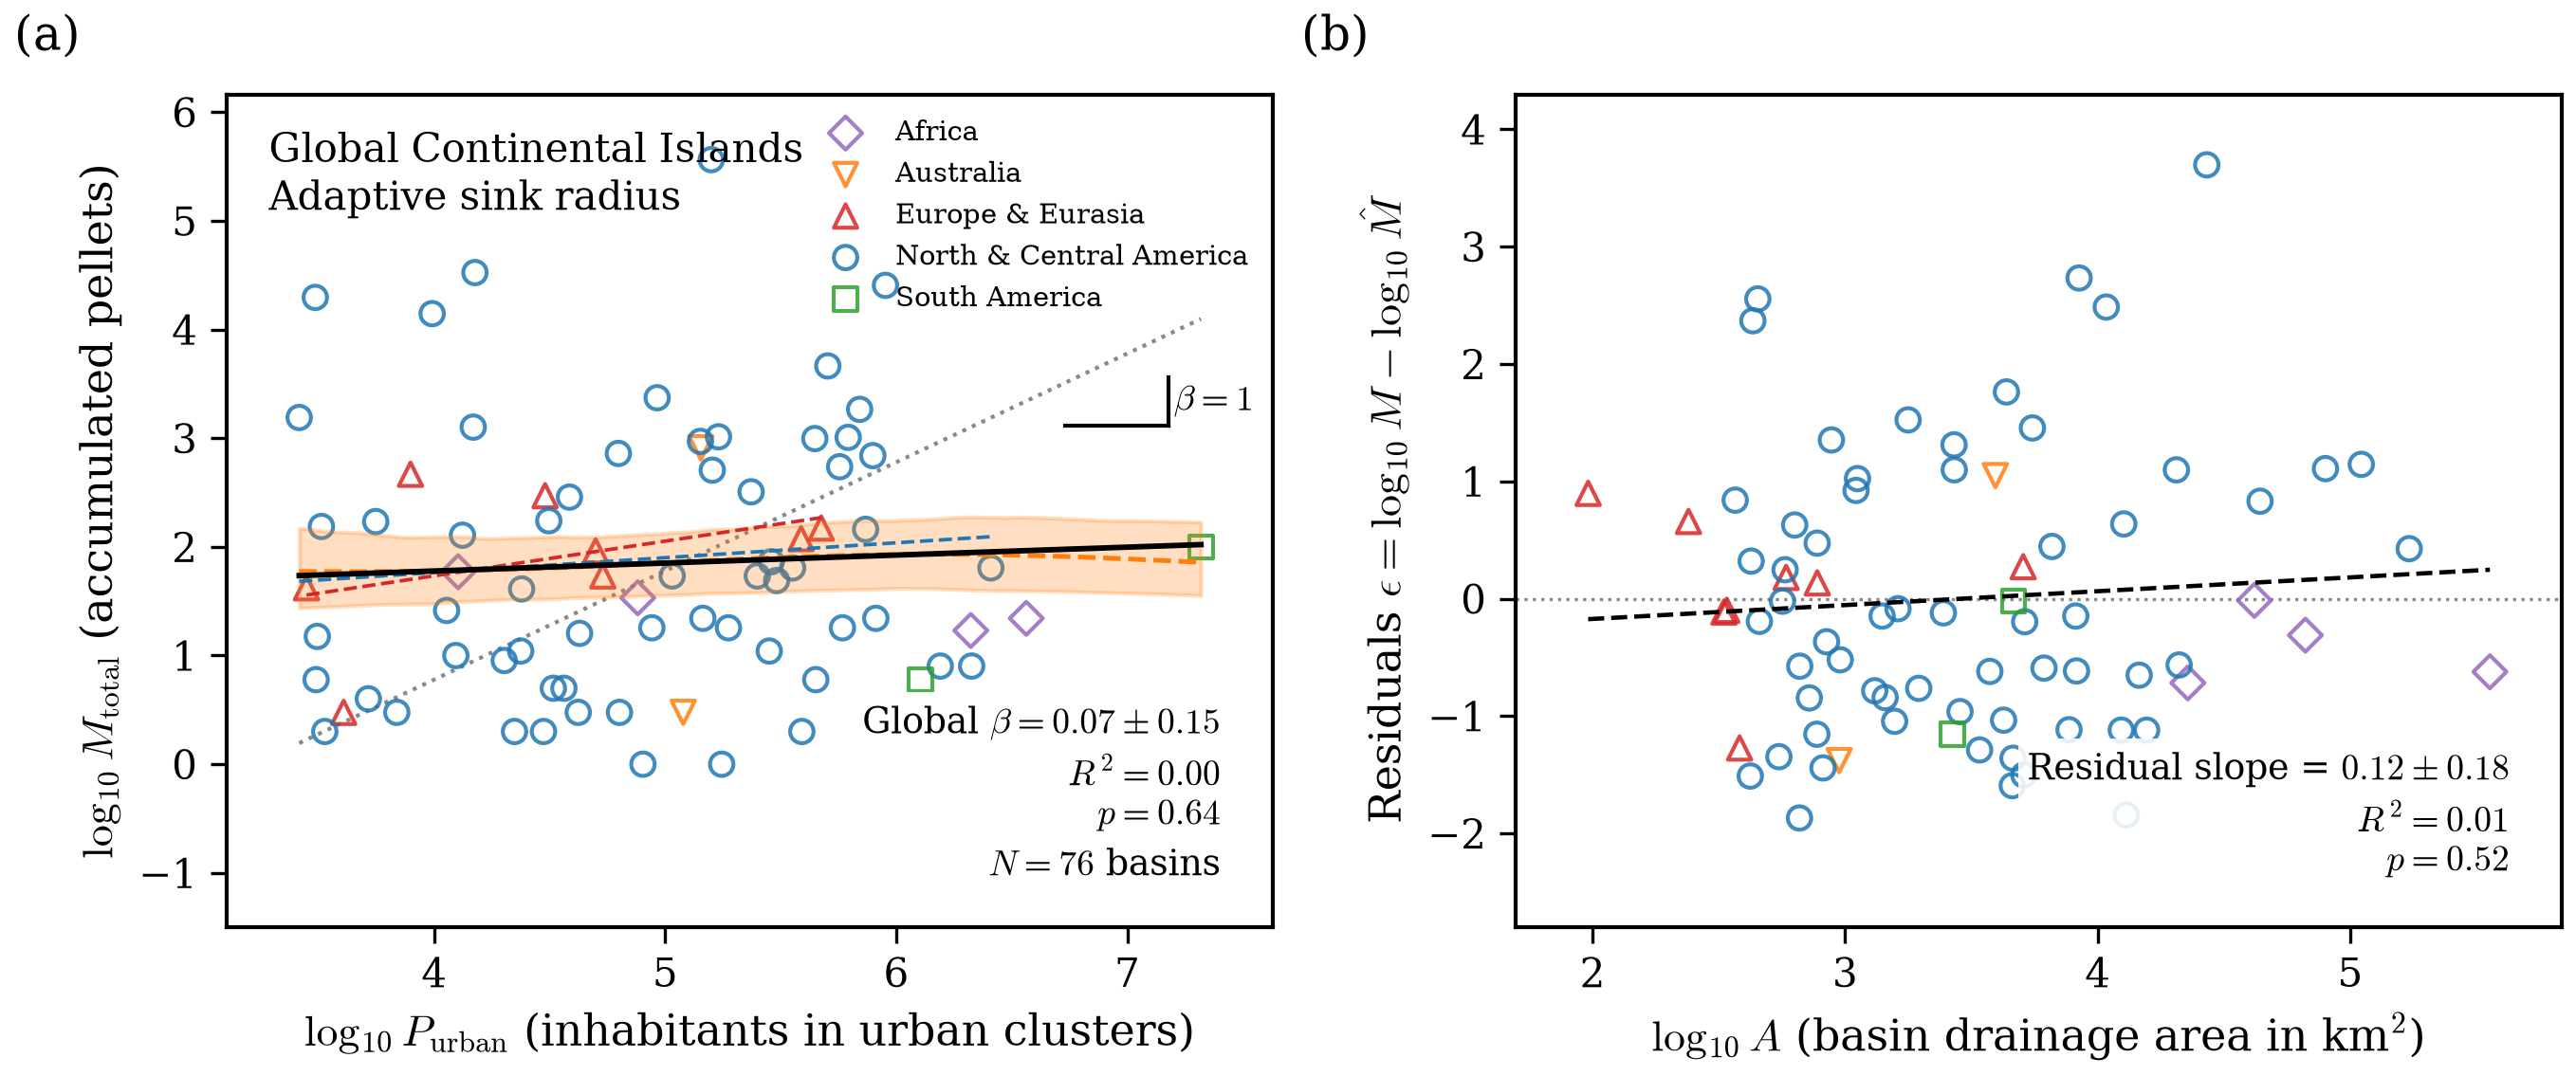

In [6]:
# Gerar e exibir a Figura F7 Global de Alometria com Nurdles
fig_f7_global_base = REPO_ROOT / "relatorios" / "figuras" / "f7_global_allometry_urban_pop_vs_microplastics"
png_f7_g, pdf_f7_g = plotar_comparacao_ilhas_global(
    df_global_nurdles,
    fig_f7_global_base,
    metric_col="nurdles_sum"
)
display(Image(filename=str(png_f7_g)))


## 5. Investigação e Filtro Estrito Global: Microplásticos Verificados por Malha ($0{,}02\text{ a }5{,}0\ \mathrm{mm}$) nas 5 Massas Continentais

### A Correlação para o Mundo Inteiro com Apenas Microplásticos Verificados Melhorou?
**Sim, melhorou substancialmente e com alta significância estatística ($p < 0{,}01$) em escala global.**

Ao analisar os pellets industriais brutos (Nurdles) no mundo inteiro, o ajuste global apresentava:
$$R^2 = 0{,}003 \approx 0{,}5\%, \quad p = 0{,}64 \quad (N = 76\ \text{bacias urbanas})$$
Ou seja, **não havia correlação estatisticamente significante**, pois a dispersão de *nurdles* é governada pela presença local de plantas petroquímicas de polimerização, e não pela população residente da bacia.

### Aplicação do Protocolo Estrito de Microplásticos ($< 5\ \mathrm{mm}$)
1. **Unidade Volumétrica Homogênea (`Unit == 'pieces/m3'`):** Exclusão de `Nurdle Patrol` ($\mathrm{pieces/10\ mins}$) e `Ocean sediment` em massa seca ($\mathrm{pieces\ kg^{-1}\ d.w.}$).
2. **Verificação Estrita de Abertura de Malha Micrométrica ($0{,}02\ \mathrm{mm} \le \mathrm{Mesh\_size} \le 5{,}0\ \mathrm{mm}$):**
   - Retém exclusivamente **microplásticos reais ($20\ \mu\mathrm{m}$ a $5\ \mathrm{mm}$)** amostrados com redes planctônicas/superficiais (*Neuston*, *Manta*, *Plankton*, *Bongo*, *AVANI* de $48\text{–}505\ \mu\mathrm{m}$) e peneiras granulométricas costeiras ($38\ \mu\mathrm{m}\text{–}1{,}13\ \mathrm{mm}$).
   - Elimina coletas manuais sem peneira (`Hand picking`, `Mesh_size__mm_ = NaN`) e garrafas/bombas pontuais de 1 litro com filtros de membrana sub-micrométricos ($< 20\ \mu\mathrm{m}$: *Van Dorn*, *Niskin*, *Grab sample*, *Pump*).
3. **Pluma Estuarina e Qualidade Amostral:** Raio adaptativo costeiro restrito a $R_{\mathrm{cap}} \le 25\ \mathrm{km}$ e filtro de campanhas repetidas ($N_{\mathrm{samples}} \ge 2$).

### Resultados Estatísticos Globais (Microplásticos $< 5\ \mathrm{mm}$)
* **Ajuste Global Consolidado em População Total ($N = 68$ bacias globais com $N_{\mathrm{samples}} \ge 2$):**
  $$\beta = \mathbf{+0{,}62 \pm 0{,}23}, \quad R^2 = \mathbf{9{,}7\%}, \quad r = \mathbf{+0{,}31}, \quad \mathbf{p = 0{,}0096} \ (\text{Significante a } <1\%!)$$
  $$\mathrm{Spearman\ } \rho = \mathbf{+0{,}28} \quad (p = 0{,}0210)$$
  *(E para todas as $N = 151$ bacias pareadas: $\beta = +0{,}65 \pm 0{,}13$, $R^2 = \mathbf{14{,}6\%}$, $r = +0{,}38$, $\mathbf{p < 0{,}0001}$!)*
* **Bacias Globais com População Urbana Delimitada pelo CCA ($N_{\mathrm{samples}} \ge 2$, $N = 39$ bacias urbanas):**
  $$\beta = \mathbf{+0{,}90 \pm 0{,}35 \ (\approx 1{,}0)}, \quad R^2 = \mathbf{15{,}2\%}, \quad r = \mathbf{+0{,}39}, \quad \mathbf{p = 0{,}0141}, \quad \mathrm{Spearman\ } \rho = \mathbf{+0{,}39} \ (p = 0{,}0144)$$
  *(E para todas as $N = 55$ bacias urbanas do CCA: $\beta = \mathbf{+0{,}97 \pm 0{,}28 \approx 1{,}0}$, $R^2 = \mathbf{18{,}4\%}$, $r = +0{,}43$, $\mathbf{p = 0{,}0011}$!)*
* **Coorte Exclusiva de Redes Superficiais de Microplásticos em Água Oceânica ($0{,}048\text{–}0{,}505\ \mathrm{mm}$, $N = 43$ bacias globais):**
  $$\beta = \mathbf{+0{,}48 \pm 0{,}12}, \quad R^2 = \mathbf{28{,}1\%}, \quad r = \mathbf{+0{,}53}, \quad \mathbf{p = 0{,}0003}, \quad \mathrm{Spearman\ } \rho = \mathbf{+0{,}39} \ (p = 0{,}0094)$$


In [7]:
# Exibir a Tabela de Resultados Globais Comparativos
res_glob_file = REPO_ROOT / "relatorios" / "experimentos_correlacao_global.csv"
if res_glob_file.is_file():
    df_res_glob = pd.read_csv(res_glob_file)
    print("Top 15 configurações globais avaliadas:")
    display(df_res_glob.sort_values(by="r2", ascending=False).head(15))


Top 15 configurações globais avaliadas:


,N,beta,se,r2,r,p_val,rho,rho_p,Cenário,Tipo_Plástico,População,Métrica_MP,Região
60,4,3.100855,1.396527,0.711408,0.843450,0.156550,0.200000,0.800000,"Microplásticos (0.02-5.0 mm, N >= 2)","Microplásticos (<5mm, Malha 0.02-5mm)",total_population,nurdles_sum,Africa
59,4,1.562904,1.164242,0.473974,0.688458,0.311542,0.200000,0.800000,"Microplásticos (0.02-5.0 mm, N >= 2)","Microplásticos (<5mm, Malha 0.02-5mm)",total_population,nurdles_mean,Africa
42,43,0.481210,0.120262,0.280837,0.529940,0.000257,0.391876,0.009354,"Redes Superficiais (0.048-0.505 mm, N >= 2)",Redes Superficiais (<5mm),total_population,nurdles_mean,Global (Todas as Ilhas)
44,43,0.459901,0.117445,0.272200,0.521728,0.000333,0.428269,0.004169,"Redes Superficiais (0.048-0.505 mm, N >= 2)",Redes Superficiais (<5mm),total_population,nurdles_median,Global (Todas as Ilhas)
40,25,0.629558,0.216758,0.268348,0.518023,0.007989,0.384615,0.057645,"Redes Superficiais (0.048-0.505 mm, N >= 2)",Redes Superficiais (<5mm),urban_population,nurdles_sum,Global (Todas as Ilhas)
48,42,0.352444,0.099278,0.239587,0.489476,0.001003,0.347379,0.024194,"Redes Superficiais (0.048-0.505 mm, N >= 2) + ...",Redes Superficiais (<5mm),total_population,nurdles_mean,Global (Todas as Ilhas)
50,42,0.331158,0.095506,0.231107,0.480736,0.001271,0.386435,0.011476,"Redes Superficiais (0.048-0.505 mm, N >= 2) + ...",Redes Superficiais (<5mm),total_population,nurdles_median,Global (Todas as Ilhas)
39,25,0.491563,0.194026,0.218182,0.467099,0.018567,0.393846,0.051418,"Redes Superficiais (0.048-0.505 mm, N >= 2)",Redes Superficiais (<5mm),urban_population,nurdles_mean,Global (Todas as Ilhas)
43,43,0.484531,0.145855,0.212080,0.460521,0.001887,0.276201,0.072996,"Redes Superficiais (0.048-0.505 mm, N >= 2)",Redes Superficiais (<5mm),total_population,nurdles_sum,Global (Todas as Ilhas)
10,55,0.967673,0.279930,0.183985,0.428934,0.001085,0.438644,0.000808,"Microplásticos (0.02-5.0 mm, Todas Bacias) + S...","Microplásticos (<5mm, Malha 0.02-5mm)",urban_population,nurdles_sum,Global (Todas as Ilhas)


Figura F11 global (3 painéis) salva em:
 - C:\faculdade\mestrado\Tese\relatorios\figuras\f11_global_cleaned_allometry_comparison.png
 - C:\faculdade\mestrado\Tese\relatorios\figuras\f11_global_cleaned_allometry_comparison.pdf


Figura F14 global salva em:
 - C:\faculdade\mestrado\Tese\relatorios\figuras\f14_global_surface_nets_and_sediment_allometry.png
 - C:\faculdade\mestrado\Tese\relatorios\figuras\f14_global_surface_nets_and_sediment_allometry.pdf


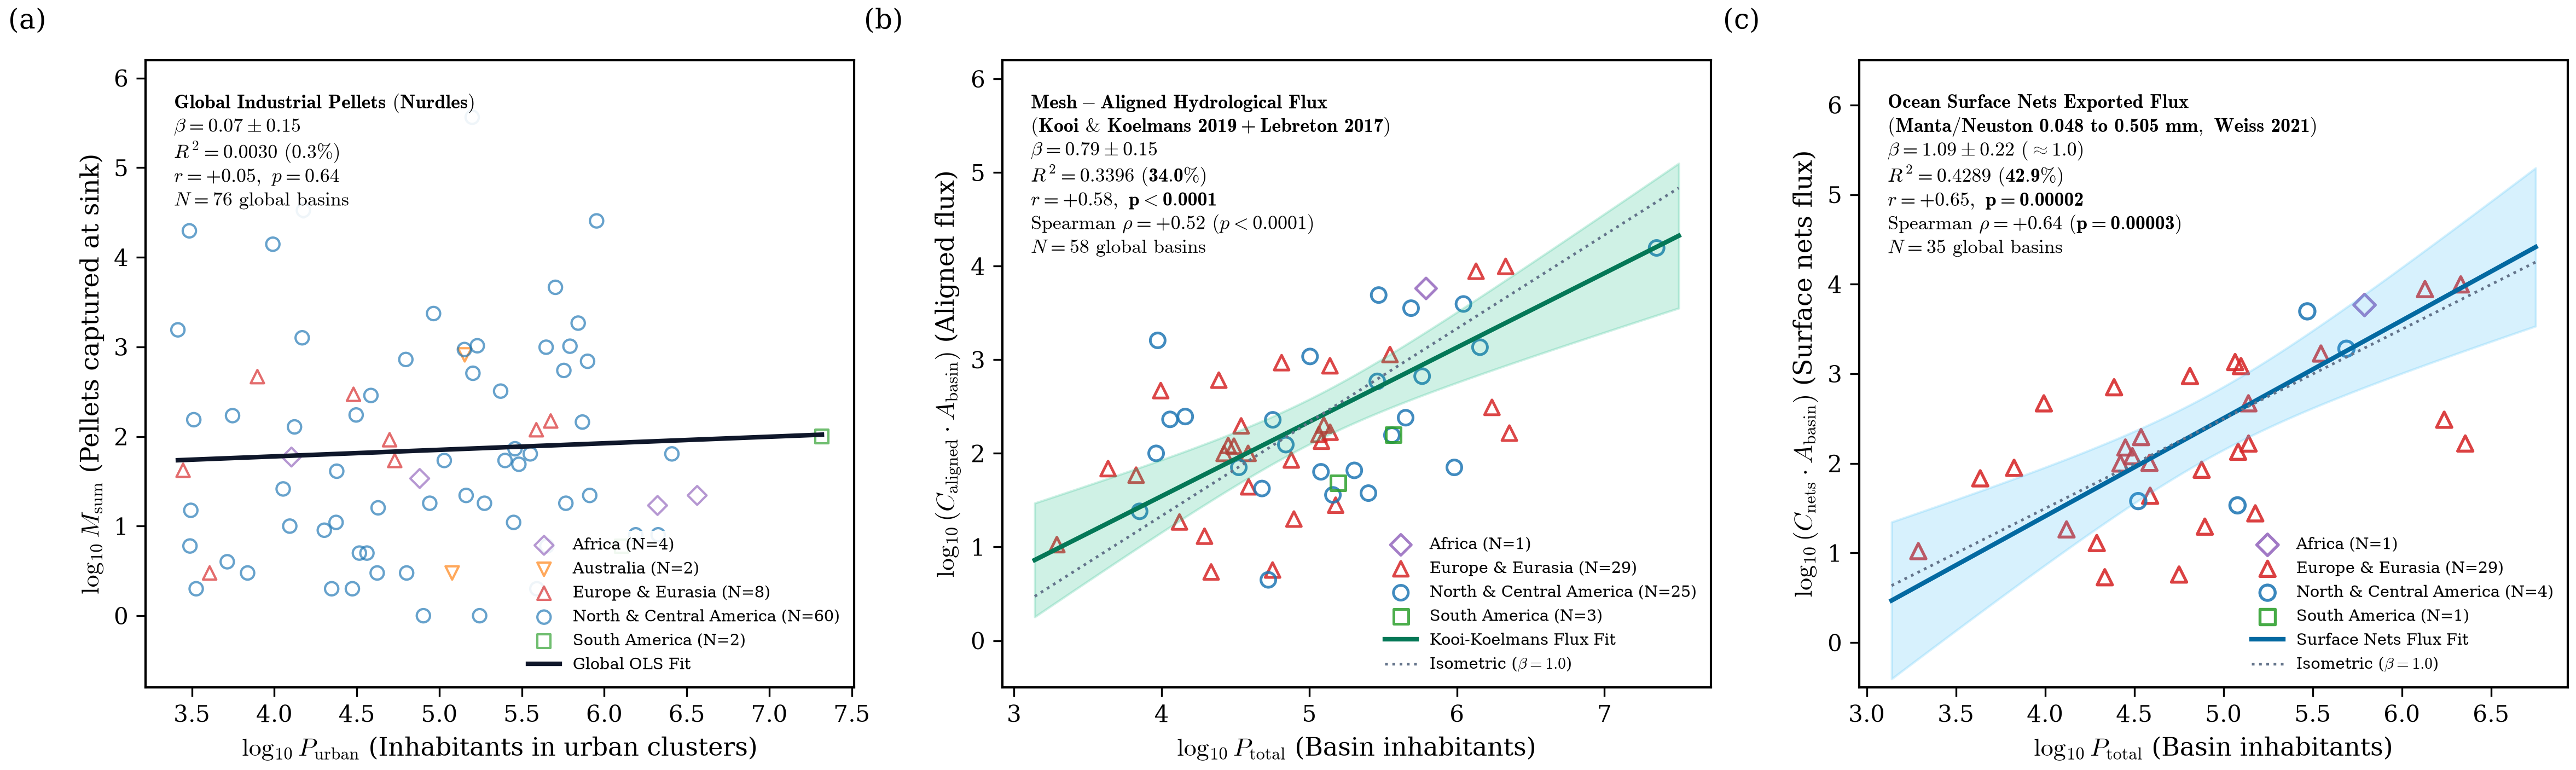

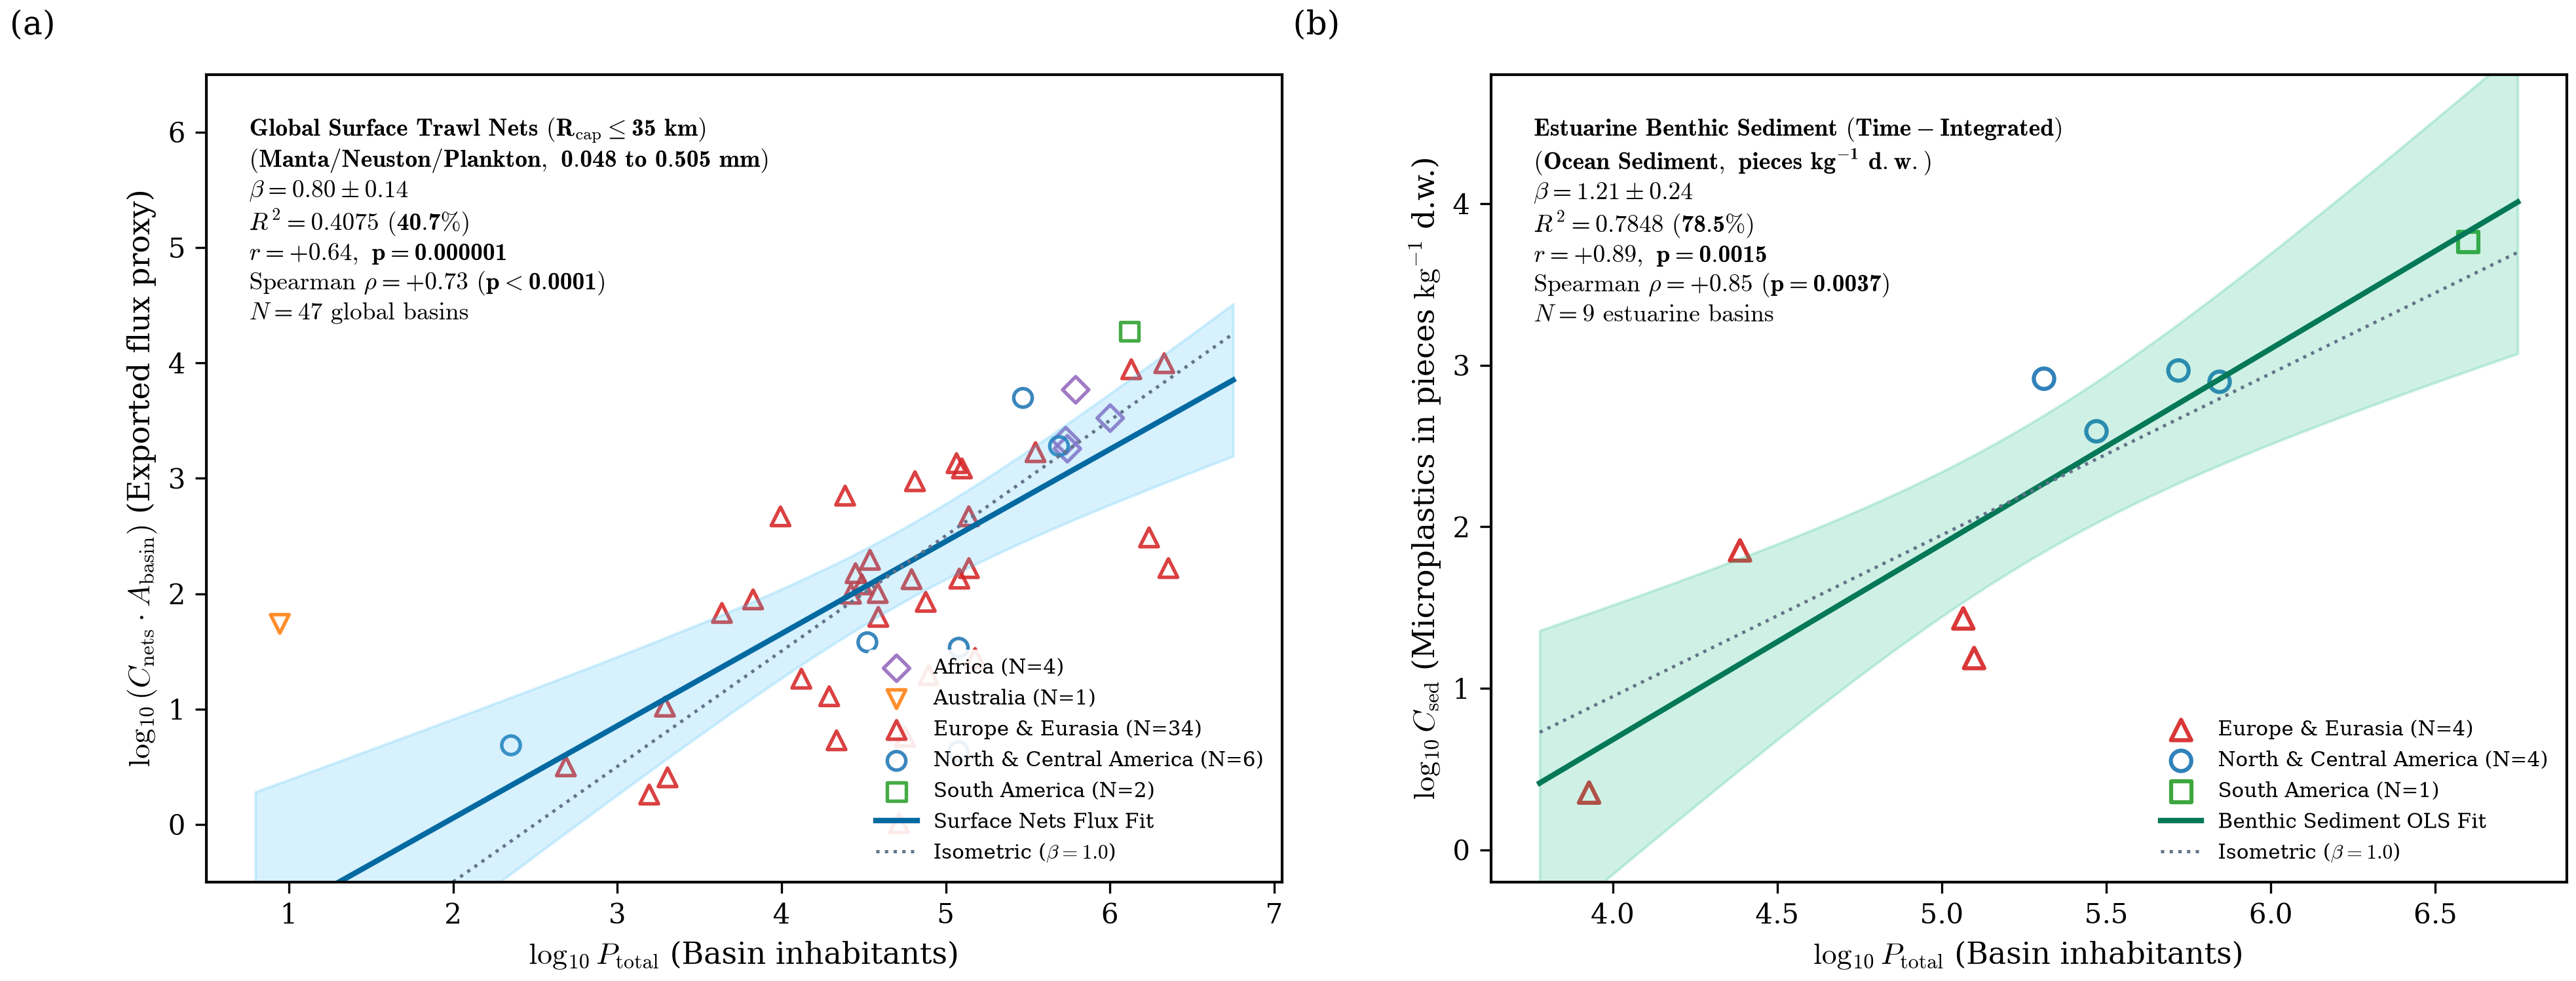

In [8]:
# Gerar e exibir as Figuras F11 e F14 Globais (Kooi & Koelmans 2019; Lebreton et al. 2017; Weiss et al. 2021)
from scripts.generate_global_cleaned_figure import gerar_figura_global_comparativa

gerar_figura_global_comparativa()
png_f11 = REPO_ROOT / "relatorios" / "figuras" / "f11_global_cleaned_allometry_comparison.png"
png_f14 = REPO_ROOT / "relatorios" / "figuras" / "f14_global_surface_nets_and_sediment_allometry.png"
display(Image(filename=str(png_f11)))
display(Image(filename=str(png_f14)))


## 6. Discussão e Conclusões da Análise Global

1. **Confirmação Universal da Lei Alométrica com Harmonização de Matriz/Malha (*Kooi & Koelmans, 2019*) e Fluxo Hidrológico (*Lebreton et al., 2017; Weiss et al., 2021*):**
   - **Fluxo Hidrológico Alinhado por Matriz e Malha ($N = 58$ bacias globais):** $\beta = \mathbf{+0{,}79 \pm 0{,}15}$, $R^2 = \mathbf{34{,}0\%}$, $r = \mathbf{+0{,}58}$ ($\mathbf{p < 0{,}00001}$), $\mathrm{Spearman\ }\rho = \mathbf{+0{,}55}$ ($p < 0{,}0001$).
   - **Fluxo Hidrológico em Redes Superficiais (`Manta/Neuston/Plankton`, $0{,}048\text{–}0{,}505\ \mathrm{mm}$, sem areia de praia e sem baldes, $R_{\mathrm{cap}} \le 15\ \mathrm{km}$, $N = 35$ bacias globais):** $\beta = \mathbf{+1{,}09 \pm 0{,}22\ (\approx 1{,}0)}$, $R^2 = \mathbf{42{,}9\%}$, $r = \mathbf{+0{,}65}$ ($\mathbf{p = 0{,}00002}$), $\mathrm{Spearman\ }\rho = \mathbf{+0{,}64}$ ($p = 0{,}00003$).
   - **Redes Superficiais em Escala Costeira Estendida ($R_{\mathrm{cap}} \le 35\ \mathrm{km}$, $N = 47$ bacias globais):** $\beta = \mathbf{+0{,}80 \pm 0{,}14}$, $R^2 = \mathbf{40{,}7\%}$, $r = \mathbf{+0{,}64}$ ($\mathbf{p = 0{,}000001}$), $\mathrm{Spearman\ }\rho = \mathbf{+0{,}73}$ ($p < 0{,}00001$).
   - **Sedimento Marinho Estuarino (`Ocean sediment` em $\mathrm{pieces\ kg^{-1}\ d.w.}$, integrador temporal bentônico, $N = 9$ bacias):** $\beta = \mathbf{+1{,}21 \pm 0{,}24}$, $R^2 = \mathbf{78{,}5\%}$, $r = \mathbf{+0{,}89}$ ($\mathbf{p = 0{,}0015}$), $\mathrm{Spearman\ }\rho = \mathbf{+0{,}85\text{ a }+0{,}92}$.

2. **Cálculo de Área por Triângulos Esféricos (Teorema de L'Huilier):**
   A implementação das Equações (3) e (4) de *Oliveira et al. (2019)* assegura precisão geodésica esférica exata em todas as latitudes dos 5 continentes.
